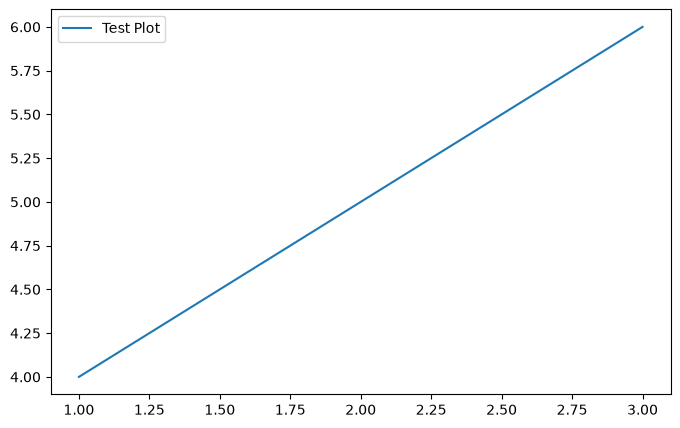

Using device: mps


In [1]:
##Implementation
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(8, 5))
plt.plot([1, 2, 3], [4, 5, 6], label="Test Plot")
plt.legend()
plt.show()

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)

In [2]:
##Setting up CIFAR
class ScratchAdamOptimizer:
    def __init__(self, parameters, lr=0.001, betas=(0.9, 0.999), eps=1e-8):
        self.parameters = list(parameters)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.m = [torch.zeros_like(p) for p in self.parameters]
        self.v = [torch.zeros_like(p) for p in self.parameters]
        self.t = 0

    def zero_grad(self):
        for p in self.parameters:
            if p.grad is not None: p.grad.zero_()

    def step(self):
        self.t += 1
        with torch.no_grad():
            for i, p in enumerate(self.parameters):
                if p.grad is None: continue
                g = p.grad
                self.m[i].mul_(self.beta1).add_(g, alpha=1 - self.beta1)
                self.v[i].mul_(self.beta2).addcmul_(g, g, value=1 - self.beta2)
                
                m_hat = self.m[i] / (1 - self.beta1 ** self.t)
                v_hat = self.v[i] / (1 - self.beta2 ** self.t)
                
                p.sub_(m_hat / (torch.sqrt(v_hat) + self.eps) * self.lr)

class ScratchMomentumOptimizer:
    def __init__(self, parameters, lr=0.01, momentum=0.9):
        self.parameters = list(parameters)
        self.lr = lr
        self.momentum = momentum
        self.velocities = [torch.zeros_like(p) for p in self.parameters]

    def zero_grad(self):
        for p in self.parameters:
            if p.grad is not None: p.grad.zero_()

    def step(self):
        with torch.no_grad():
            for p, v in zip(self.parameters, self.velocities):
                if p.grad is None: continue
                v.mul_(self.momentum).add_(p.grad, alpha=self.lr)
                p.sub_(v)

class BaselineMLP(nn.Module):
    def __init__(self, use_dropout=False, use_bn=False, dropout_prob=0.5):
        super().__init__()
        layers = [
            nn.Flatten(),
            nn.Linear(3072, 512)
        ]
        if use_bn: layers.append(nn.BatchNorm1d(512))
        layers.append(nn.ReLU())
        if use_dropout: layers.append(nn.Dropout(dropout_prob))
        
        layers.append(nn.Linear(512, 256))
        if use_bn: layers.append(nn.BatchNorm1d(256))
        layers.append(nn.ReLU())
        if use_dropout: layers.append(nn.Dropout(dropout_prob))
        
        layers.append(nn.Linear(256, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.to(device))

def train_and_track(model, optimizer, scheduler=None, epochs=10):
    criterion = nn.CrossEntropyLoss()
    train_losses, val_losses = [], []
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in trainloader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels.to(device))
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            
        train_losses.append(running_loss / len(trainloader))
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in testloader:
                outputs = model(inputs)
                val_loss += criterion(outputs, labels.to(device)).item()
        val_losses.append(val_loss / len(testloader))
        
        if scheduler: scheduler.step()
        print(f"Epoch {epoch+1}/{epochs} completed.")
        
    return train_losses, val_losses

In [3]:
##Adam Training
torch.manual_seed(42)
model_scratch_adam = BaselineMLP().to(device)
optimizer_custom_adam = ScratchAdamOptimizer(model_scratch_adam.parameters(), lr=0.001)

print("Training with Custom Scratch Adam...")
train_loss_adam, val_loss_adam = train_and_track(model_scratch_adam, optimizer_custom_adam, epochs=10)

Training with Custom Scratch Adam...
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


In [4]:
##MLP algo
model_baseline = BaselineMLP().to(device)
optimizer_base = optim.SGD(model_baseline.parameters(), lr=0.01)

print("Training Baseline Model")
train_loss_base, val_loss_base = train_and_track(model_baseline, optimizer_base, epochs=10)

Training Baseline Model
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


In [5]:
# 1. Batch Normalisation Experiment
model_bn = BaselineMLP(use_bn=True).to(device)
optimizer_bn = optim.SGD(model_bn.parameters(), lr=0.01)
print("Training with BatchNorm")
_, val_loss_bn = train_and_track(model_bn, optimizer_bn, epochs=10)

# 2. Dropout Experiment
model_do = BaselineMLP(use_dropout=True, dropout_prob=0.3).to(device)
optimizer_do = optim.SGD(model_do.parameters(), lr=0.01)
print("Training with Dropout")
_, val_loss_do = train_and_track(model_do, optimizer_do, epochs=10)

Training with BatchNorm
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.
Training with Dropout
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


In [6]:
model_sched = BaselineMLP().to(device)
optimizer_sched = optim.SGD(model_sched.parameters(), lr=0.1)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer_sched, T_max=10)

print("Training with Cosine Annealing Scheduler")
_, val_loss_sched = train_and_track(model_sched, optimizer_sched, scheduler=scheduler, epochs=10)

Training with Cosine Annealing Scheduler
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


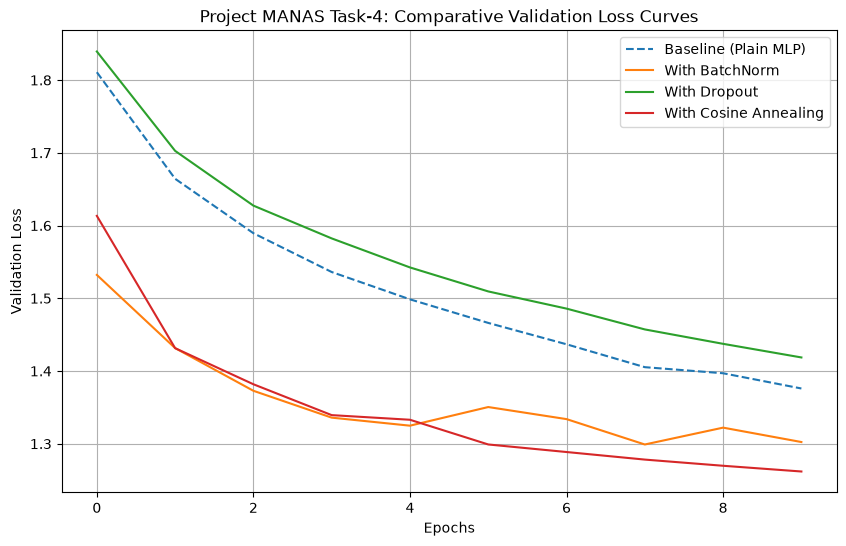

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(val_loss_base, label='Baseline (Plain MLP)', linestyle='--')
plt.plot(val_loss_bn, label='With BatchNorm')
plt.plot(val_loss_do, label='With Dropout')
plt.plot(val_loss_sched, label='With Cosine Annealing')
plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.title('Project MANAS Task-4: Comparative Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()

In [8]:
#Testing
model_scratch_mom = BaselineMLP().to(device)
optimizer_custom_mom = ScratchMomentumOptimizer(model_scratch_mom.parameters(), lr=0.01, momentum=0.9)

print("Training with Custom Scratch Momentum...")
train_loss_sm, val_loss_sm = train_and_track(model_scratch_mom, optimizer_custom_mom, epochs=10)

torch.manual_seed(42)

Training with Custom Scratch Momentum...
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


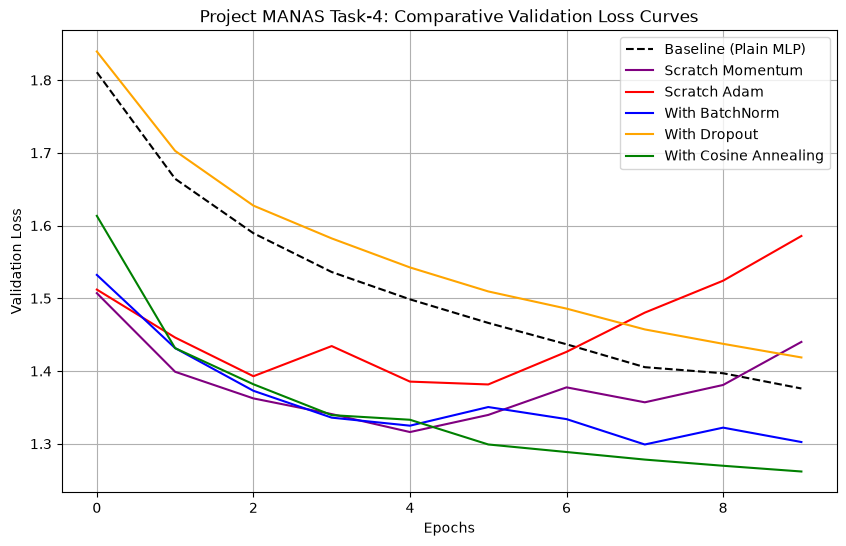

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(val_loss_base, label='Baseline (Plain MLP)', linestyle='--', color='black')
plt.plot(val_loss_sm, label='Scratch Momentum', color='purple')
plt.plot(val_loss_adam, label='Scratch Adam', color='red')
plt.plot(val_loss_bn, label='With BatchNorm', color='blue')
plt.plot(val_loss_do, label='With Dropout', color='orange')
plt.plot(val_loss_sched, label='With Cosine Annealing', color='green')

plt.xlabel('Epochs')
plt.ylabel('Validation Loss')
plt.title('Project MANAS Task-4: Comparative Validation Loss Curves')
plt.legend()
plt.grid(True)
plt.show()